# Дизайн A/B-теста

У компании есть клиенты, которые покупают товар и у нас, и у конкурентов. Мы хотим запустить пилот, который должен увеличить долю покупок у нас. Мы хотим понять две вещи:

1. Какой минимальный эффект (MDE) тест сможет поймать, если идет месяц.
2. Сколько должен идти тест, чтобы поймать эффект в 1 процентный пункт.

План:

1. Анализируем данные
2. Формулируем метрику и единицу сплитования
3. Считаем MDE за месяц
4. Считаем, как MDE зависит от длительности теста
5. Выводы и рекомендации

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.stats.power import TTestIndPower

## 1. Данные

Одна строка это одна покупка. Какой клиент, когда и у кого купил, то есть у нас или у конкурента.

In [2]:
purchases = pd.read_csv("purchases.csv", encoding="cp1251", sep=";")
purchases["purchase_date"] = pd.to_datetime(purchases["purchase_date"], format="%d.%m.%Y")
purchases["is_us"] = (purchases["seller"] == "У нас").astype(int)
purchases["month"] = purchases["purchase_date"].dt.to_period("M")

purchases.head()

,client_id,purchase_date,seller,is_us,month
0,CUST_00001,2023-03-05,Конкурент,0,2023-03
1,CUST_00001,2023-12-15,У нас,1,2023-12
2,CUST_00001,2023-08-17,У нас,1,2023-08
3,CUST_00001,2023-04-18,Конкурент,0,2023-04
4,CUST_00002,2023-05-04,У нас,1,2023-05


In [3]:
print(f"Покупок: {len(purchases)}")
print(f"Клиентов: {purchases['client_id'].nunique()}")
print(f"Период: с {purchases['purchase_date'].min():%d.%m.%Y} по {purchases['purchase_date'].max():%d.%m.%Y}")
print(f"Доля покупок у нас: {purchases['is_us'].mean():.1%}")

Покупок: 17890
Клиентов: 5000
Период: с 18.12.2022 по 13.01.2024
Доля покупок у нас: 35.7%


In [4]:
purchases.groupby("month").agg(
    покупок=("is_us", "size"),
    клиентов=("client_id", "nunique"),
    доля_у_нас=("is_us", "mean"),
).round(3)

,покупок,клиентов,доля_у_нас
month,,,
2022-12,169,166,0.308
2023-01,1350,1178,0.357
2023-02,1384,1209,0.359
2023-03,1557,1330,0.349
2023-04,1482,1274,0.353
2023-05,1525,1324,0.363
2023-06,1535,1321,0.343
2023-07,1477,1296,0.364
2023-08,1483,1291,0.378


Что это значит:

- Декабрь 2022 и январь 2024 неполные, данные начинаются 18 декабря и заканчиваются 13 января. Посмотрим только 12 полных месяцев 2023 года, иначе неполные месяцы занизят средние.
- В каждом полном месяце примерно 1 300 активных клиентов и около 1 500 покупок.
- Доля покупок у нас держится около 35-36% и почти не скачет от месяца к месяцу.

  Новых клиентов почти не прибавляется, покупают в основном одни и те же люди

In [5]:
# оставляем только полные месяцы 2023 года
purchases = purchases[(purchases["month"] >= "2023-01") & (purchases["month"] <= "2023-12")]

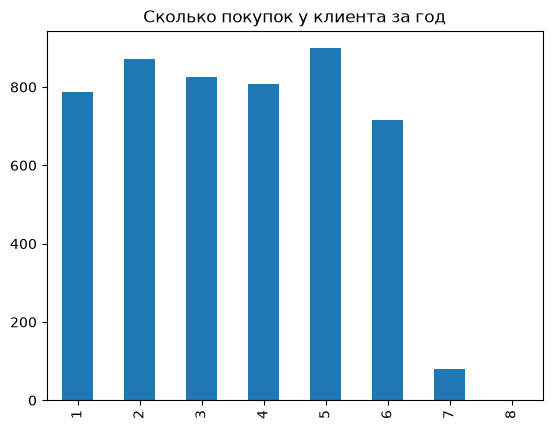

In [6]:
purchases.groupby("client_id").size().value_counts().sort_index().plot(kind="bar")
plt.title("Сколько покупок у клиента за год")
plt.show()

## 2. Метрика и единица сплитования

- **Метрика** это число покупок у нас, деленное на общее число покупок.
- **Единица сплитования** это клиент. Клиента случайно отправляем в контроль или в тест, и все его покупки попадают в ту же группу.

Метрика это покупки у нас делить на все покупки, а сплитуем мы по клиентам. Значит, и числитель, и знаменатель зависят от того, какие клиенты попали в группу. Значит, это ratio-метрика. Поэтому нельзя просто взять все покупки и сравнить доли обычным тестом.

Поэтому используем линеаризацию. Для каждого клиента считаем одно число:

`lin = (x - R * y) / mean(y)`

- `x` это покупки клиента у нас
- `y` это все покупки клиента
- `R` это доля покупок у нас по всем клиентам
- `mean(y)` это среднее число покупок на клиента

Получается обычная метрика на клиента, ее среднее около нуля, а разброс такой же, как у исходной доли. Дальше с ней работают стандартные формулы.

Стоит отметить что `R` и `mean(y)` надо считать на тех же данных, что и метрику. Если тест длится месяц, то и покупки клиента, и среднее берем за месяц.

## 3. MDE за месяц

Возьмем стандратные значения, уровень значимости 5%, мощность 80%, клиенты делятся пополам.

Считаем MDE отдельно для каждого месяца 2023 года, в каждом свое число клиентов и свой разброс. Потом смотрим на среднее.

In [7]:
power = TTestIndPower()

rows = []
for month, month_purchases in purchases.groupby("month"):
    clients = month_purchases.groupby("client_id").agg(x=("is_us", "sum"), y=("is_us", "size"))
    R = clients["x"].sum() / clients["y"].sum()
    lin = (clients["x"] - R * clients["y"]) / clients["y"].mean()

    effect_size = power.solve_power(effect_size=None, nobs1=len(clients) / 2, alpha=0.05, power=0.8)
    rows.append({"месяц": str(month), "клиентов": len(clients), "MDE, п.п.": effect_size * lin.std() * 100})

monthly = pd.DataFrame(rows).round(2)
monthly

,месяц,клиентов,"MDE, п.п."
0,2023-01,1178,7.51
1,2023-02,1209,7.13
2,2023-03,1330,6.65
3,2023-04,1274,6.98
4,2023-05,1324,6.84
5,2023-06,1321,6.78
6,2023-07,1296,7.06
7,2023-08,1291,7.08
8,2023-09,1268,7.01
9,2023-10,1352,6.88


In [8]:
print(f"Средний MDE за месяц: {monthly['MDE, п.п.'].mean():.1f} п.п.")

Средний MDE за месяц: 7.0 п.п.


За месяц тест надежно заметит только изменение доли покупок примерно на 7 п.п., то есть с 35.7% до 43% и выше. Все, что меньше, просто утонет в шуме.

Для сравнения посчитаем MDE по обычной формуле для долей, как будто наблюдение это покупка, а не клиент. Вообще так делать нельзя, но интересно посмотреть, насколько ошибемся.

In [9]:
p = purchases["is_us"].mean()
purchases_per_group = purchases.groupby("month").size().mean() / 2

effect_size = power.solve_power(effect_size=None, nobs1=purchases_per_group, alpha=0.05, power=0.8)
mde_simple = effect_size * np.sqrt(p * (1 - p)) * 100
print(f"MDE по формуле для долей: {mde_simple:.1f} п.п.")

MDE по формуле для долей: 7.0 п.п.


Получаются те же 7 п.п. Это потому, что за месяц у клиента в среднем чуть больше одной покупки, и разницы между клиентом и покупкой почти нет. Если бы клиенты покупали часто и у каждого была своя привычка, обычная формула дала бы MDE меньше реального, и мы бы зря надеялись поймать маленький эффект.

## 4. MDE от длительности теста

Чем дольше идет тест, тем больше клиентов успевает в него попасть и тем больше у каждого покупок. MDE от этого падает.

Посчитаем, какие клиенты попадут в тест и какое MDE мы можем засечь, если тест стартует в начале года и идет разное количество месяцев, от 1 до 12.

In [10]:
rows = []
for months in range(1, 13):
    window = purchases[purchases["month"] <= pd.Period("2023-01", "M") + (months - 1)]

    clients = window.groupby("client_id").agg(x=("is_us", "sum"), y=("is_us", "size"))
    R = clients["x"].sum() / clients["y"].sum()
    lin = (clients["x"] - R * clients["y"]) / clients["y"].mean()

    effect_size = power.solve_power(effect_size=None, nobs1=len(clients) / 2, alpha=0.05, power=0.8)
    rows.append({"месяцев": months, "клиентов": len(clients), "MDE, п.п.": effect_size * lin.std() * 100})

by_duration = pd.DataFrame(rows).round(2)
by_duration

,месяцев,клиентов,"MDE, п.п."
0,1,1178,7.51
1,2,2096,5.18
2,3,2847,4.07
3,4,3412,3.53
4,5,3850,3.12
5,6,4128,2.82
6,7,4371,2.64
7,8,4554,2.47
8,9,4705,2.33
9,10,4822,2.20


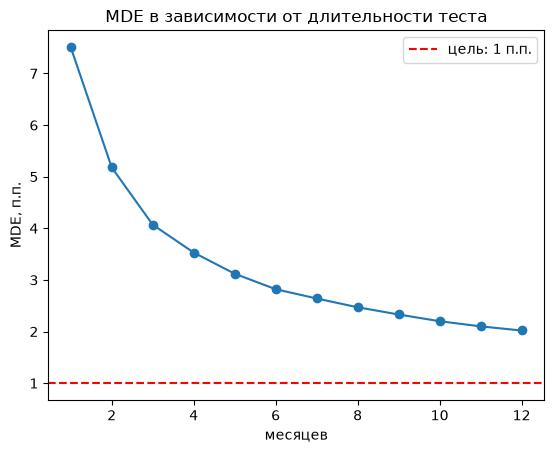

In [11]:
plt.plot(by_duration["месяцев"], by_duration["MDE, п.п."], marker="o")
plt.axhline(1, color="red", linestyle="--", label="цель: 1 п.п.")
plt.title("MDE в зависимости от длительности теста")
plt.xlabel("месяцев")
plt.ylabel("MDE, п.п.")
plt.legend()
plt.show()

Что видно:

- Первые месяцы MDE падает быстро, с 7.5 п.п. за месяц до 4 п.п. за три месяца.
- Потом падение замедляется, и тут две причины. Новых клиентов почти не остается, база заканчивается. А еще MDE в принципе уменьшается медленно. Чтобы уменьшить его в 2 раза, нужно в 4 раза больше клиентов. Ниже это видно на графике.
- Даже если держать тест весь год, в него попадет почти вся база, и MDE будет около 2 п.п.

Посчитаем, сколько клиентов нужно, чтобы поймать 1 п.п.

In [12]:
clients = purchases.groupby("client_id").agg(x=("is_us", "sum"), y=("is_us", "size"))
R = clients["x"].sum() / clients["y"].sum()
lin = (clients["x"] - R * clients["y"]) / clients["y"].mean()

n_needed = power.solve_power(effect_size=0.01 / lin.std(), nobs1=None, alpha=0.05, power=0.8)

print(f"Нужно клиентов всего: {2 * n_needed:.0f}")
print(f"Есть клиентов в базе: {len(clients)}")

Нужно клиентов всего: 20397
Есть клиентов в базе: 4986


Почему так много? MDE зависит от числа клиентов как единица, деленная на корень из этого числа. Поэтому нужное число клиентов растет не линейно, а квадратично.

Посмотрим на графике, сколько клиентов нужно для разного MDE.

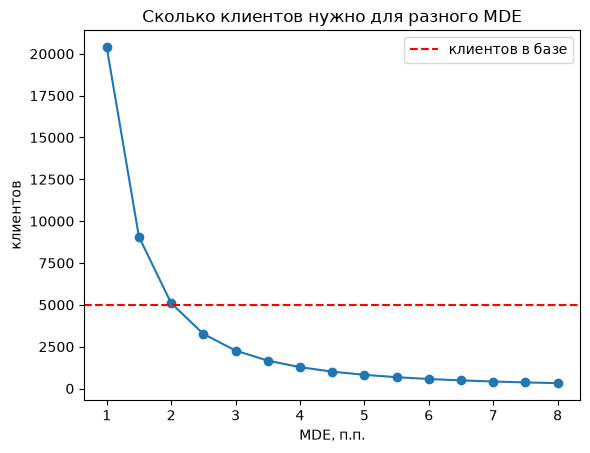

In [13]:
target_mde = np.arange(1, 8.5, 0.5)   # MDE, п.п.
clients_needed = [2 * power.solve_power(effect_size=m / 100 / lin.std(), nobs1=None, alpha=0.05, power=0.8) for m in target_mde]

plt.plot(target_mde, clients_needed, marker="o")
plt.axhline(len(clients), color="red", linestyle="--", label="клиентов в базе")
plt.title("Сколько клиентов нужно для разного MDE")
plt.xlabel("MDE, п.п.")
plt.ylabel("клиентов")
plt.legend()
plt.show()

Красная линия это вся наша база, почти 5 000 клиентов. Все, что выше нее, на этих данных недостижимо. MDE в 2 п.п. как раз на границе, для него нужно около 5 100 клиентов. А дальше кривая резко уходит вверх, для 1.5 п.п. нужно уже около 9 000, а для 1 п.п. больше 20 000.

## 5. Выводы

- **За месяц** тест поймает только крупное изменение доли покупок, около 7 п.п. Более мелкие изменения утонут в шуме.
- **Эффект в 1 п.п. на этой базе поймать нельзя.** Даже если тест идет весь год и в него попадают почти все клиенты, MDE остается около 2 п.п. Для 1 п.п. нужно около 20 тысяч клиентов, примерно в четыре раза больше, чем есть.
- Держать тест дольше пары месяцев к тому же нерационально, ведь результат нужен бизнесу раньше, а выигрыш в чувствительности после 3-4 месяцев небольшой.

Что можно сделать:

- **Запускать тест на изменения с большим ожидаемым эффектом**, от 4-5 п.п., тогда хватит двух-трех месяцев.
- **Найти более чувствительную прокси-метрику** на ранних этапах воронки, где больше событий и легче набрать выборку.
- **Расширить аудиторию теста**, если в реальности новые клиенты приходят. В этой выгрузке база фиксированная, но в живом продукте это может быть не так.